# 04 - Data Quality

Audit 100 synthetic news articles against a balanced sample from [AG News](https://huggingface.co/datasets/fancyzhx/ag_news). Check integrity, length, lexical and sentence-embedding diversity, labels, and realism.

In [1]:
from pathlib import Path
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data" / "synthetic" / "pilot_100.csv").exists())
CATEGORIES = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
synthetic = pd.read_csv(ROOT / "data" / "synthetic" / "pilot_100.csv")
assert len(synthetic) == 100
assert synthetic.groupby("label").size().to_dict() == {label: 25 for label in CATEGORIES}

AG_NEWS_API = "https://datasets-server.huggingface.co/rows"
OFFSETS = range(0, 120000, 15000)  # eight fixed 100-row windows from the train split
real_rows = []
with requests.Session() as session:
    for offset in OFFSETS:
        response = session.get(AG_NEWS_API, params={
            "dataset": "fancyzhx/ag_news", "config": "default",
            "split": "train", "offset": offset, "length": 100,
        }, timeout=30)
        response.raise_for_status()
        page = response.json()["rows"]
        assert len(page) == 100 and all(not item["truncated_cells"] for item in page)
        real_rows.extend({"row_idx": item["row_idx"], **item["row"]} for item in page)
real_pool = pd.DataFrame(real_rows)
real_pool["category"] = real_pool.label.map(CATEGORIES)
real = (real_pool.groupby("label", group_keys=False)
        .sample(n=25, random_state=42).sort_values(["label", "row_idx"]))
assert len(real) == 100 and real.label.value_counts().eq(25).all()
print("Synthetic:", len(synthetic), "| Real comparison:", len(real),
      "| Real screening pool:", len(real_pool))

Synthetic: 100 | Real comparison: 100 | Real screening pool: 800


In [2]:
data = pd.concat([
    synthetic[["label", "category", "text"]].assign(source="Synthetic"),
    real[["label", "category", "text"]].assign(source="AG News"),
], ignore_index=True)

integrity = []
for source, frame in data.groupby("source"):
    text = frame.text.fillna("").astype(str)
    normalized = text.str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
    integrity.append({
        "source": source, "rows": len(frame),
        "missing_text": frame.text.isna().sum(),
        "blank_text": text.str.strip().eq("").sum(),
        "missing_label": frame.label.isna().sum(),
        "exact_duplicate_text": normalized.duplicated().sum(),
    })
display(pd.DataFrame(integrity))
class_counts = data.groupby(["source", "category"]).size().unstack(fill_value=0)
display(class_counts)

WORD = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)?", re.UNICODE)
def words(text):
    return WORD.findall(str(text).lower())

data["word_count"] = data.text.map(lambda text: len(words(text)))
lengths = data.groupby("source").word_count.agg(
    count="count", mean="mean", median="median", minimum="min", maximum="max"
)
lengths["p95"] = data.groupby("source").word_count.quantile(0.95)
display(lengths.round(1))

,source,rows,missing_text,blank_text,missing_label,exact_duplicate_text
0,AG News,100,0,0,0,0
1,Synthetic,100,0,0,0,0


category,Business,Sci/Tech,Sports,World
source,,,,
AG News,25,25,25,25
Synthetic,25,25,25,25


,count,mean,median,minimum,maximum,p95
source,,,,,,
AG News,100,38.8,39.0,16,68,51.1
Synthetic,100,54.5,54.0,44,66,61.0


In [3]:
def distinct_2(texts):
    bigrams = [pair for text in texts
               for pair in zip(words(text)[:35], words(text)[1:35])]
    return len(set(bigrams)) / len(bigrams) if bigrams else np.nan

lexical = pd.DataFrame([
    {"source": source, "category": category,
     "distinct_2_first35": distinct_2(group.text.tolist())}
    for (source, category), group in data.groupby(["source", "category"])
])
display(lexical.pivot(index="category", columns="source", values="distinct_2_first35").round(3))

frequencies = {}
for source, frame in data.groupby("source"):
    frequencies[source] = Counter(
        word for text in frame.text for word in words(text)
        if len(word) > 2 and word not in ENGLISH_STOP_WORDS
    )
common_terms = list(dict.fromkeys(
    [word for word, _ in frequencies["Synthetic"].most_common(6)] +
    [word for word, _ in frequencies["AG News"].most_common(6)]
))
word_distribution = pd.DataFrame({
    source: [frequencies[source][term] / sum(frequencies[source].values())
             for term in common_terms]
    for source in ("AG News", "Synthetic")
}, index=common_terms)
display(word_distribution.round(3))

source,AG News,Synthetic
category,,
Business,0.906,0.369
Sci/Tech,0.930,0.353
Sports,0.942,0.404
World,0.952,0.384


,AG News,Synthetic
climate,0.000,0.021
james,0.000,0.013
lebron,0.000,0.013
global,0.000,0.012
record,0.000,0.012
new,0.013,0.012
said,0.008,0.000
reuters,0.005,0.000
president,0.005,0.000
quot,0.005,0.000


In [4]:
EMBED_MODEL = "all-minilm"
OLLAMA_API = "http://127.0.0.1:11434"
with requests.Session() as session:
    tags = session.get(f"{OLLAMA_API}/api/tags", timeout=10)
    tags.raise_for_status()
    embed_record = next((item for item in tags.json()["models"]
                         if item["name"] in (EMBED_MODEL, f"{EMBED_MODEL}:latest")), None)
    if embed_record is None:
        raise RuntimeError("Install the sentence embedding model: ollama pull all-minilm")

    all_texts = synthetic.text.tolist() + real_pool.text.tolist()
    chunks = []
    for start in range(0, len(all_texts), 50):
        response = session.post(f"{OLLAMA_API}/api/embed", json={
            "model": EMBED_MODEL, "input": all_texts[start:start + 50],
        }, timeout=180)
        response.raise_for_status()
        chunks.append(np.asarray(response.json()["embeddings"], dtype=np.float32))
embeddings = np.vstack(chunks)
assert embeddings.shape[0] == len(all_texts)
embeddings /= np.maximum(np.linalg.norm(embeddings, axis=1, keepdims=True), 1e-12)
syn_vectors = embeddings[:len(synthetic)]
real_vectors = embeddings[len(synthetic):]
print("Embedding model:", embed_record["name"], "| Digest:", embed_record["digest"],
      "| Vectors:", embeddings.shape)

Embedding model: all-minilm:latest | Digest: 1b226e2802dbb772b5fc32a58f103ca1804ef7501331012de126ab22f67475ef | Vectors: (900, 384)


In [5]:
def diversity(vectors):
    similarity = vectors @ vectors.T
    upper = similarity[np.triu_indices(len(vectors), k=1)]
    return float(1 - upper.mean()), int((upper >= 0.90).sum())

semantic_rows = []
for label, category in CATEGORIES.items():
    for source, vectors in (
        ("Synthetic", syn_vectors[synthetic.label.to_numpy() == label]),
        ("AG News", real_vectors[real.index[real.label == label].to_numpy()]),
    ):
        score, near_pairs = diversity(vectors)
        semantic_rows.append({"source": source, "category": category,
                              "semantic_diversity": score,
                              "near_duplicate_pairs_cosine_0_90": near_pairs})
semantic = pd.DataFrame(semantic_rows)
display(semantic.round(3))

train_ids, test_ids = train_test_split(
    np.arange(len(real_pool)), test_size=0.2, random_state=42,
    stratify=real_pool.label,
)
classifier = LogisticRegression(max_iter=1000, class_weight="balanced")
classifier.fit(real_vectors[train_ids], real_pool.label.iloc[train_ids])
held_out = classifier.predict(real_vectors[test_ids])
print("Real AG News held-out label check: accuracy =",
      round(accuracy_score(real_pool.label.iloc[test_ids], held_out), 3),
      "macro-F1 =", round(f1_score(real_pool.label.iloc[test_ids], held_out,
                                   average="macro"), 3))
classifier.fit(real_vectors, real_pool.label)
probabilities = classifier.predict_proba(syn_vectors)
predicted = classifier.classes_[probabilities.argmax(axis=1)]
assigned_prob = probabilities[np.arange(len(synthetic)), synthetic.label.to_numpy()]
predicted_prob = probabilities.max(axis=1)
label_candidates = synthetic.loc[predicted != synthetic.label.to_numpy(),
                                 ["sample_id", "category", "headline"]].copy()
label_candidates["predicted_category"] = [CATEGORIES[int(label)] for label in predicted[predicted != synthetic.label.to_numpy()]]
label_candidates["confidence_gap"] = (predicted_prob - assigned_prob)[predicted != synthetic.label.to_numpy()]
print("Potential label mismatches (classifier screening):", len(label_candidates))
display(label_candidates.sort_values("confidence_gap", ascending=False).head(10).round(3))

,source,category,semantic_diversity,near_duplicate_pairs_cosine_0_90
0,Synthetic,World,0.258,61
1,AG News,World,0.922,0
2,Synthetic,Sports,0.359,55
3,AG News,Sports,0.879,0
4,Synthetic,Business,0.374,45
5,AG News,Business,0.883,0
6,Synthetic,Sci/Tech,0.507,45
7,AG News,Sci/Tech,0.885,0


Real AG News held-out label check: accuracy = 0.838 macro-F1 = 0.844
Potential label mismatches (classifier screening): 18


,sample_id,category,headline,predicted_category,confidence_gap
71,2_022,Business,Tech Giant Announces Record-Quality AI Chip La...,Sci/Tech,0.801
74,2_025,Business,Tech Giant Announces Record-Quality AI Chip fo...,Sci/Tech,0.729
61,2_012,Business,Tech Giant Announces Major Expansion of AI Res...,Sci/Tech,0.561
57,2_008,Business,Tech Giant Announces $2 Billion Investment in ...,Sci/Tech,0.460
53,2_004,Business,Tech Giant Reports Record Q4 Earnings Amid AI ...,Sci/Tech,0.279
60,2_011,Business,Tech Giant Announces $2 Billion Investment in ...,Sci/Tech,0.221
55,2_006,Business,Tech Giant Reports Record Quarterly Earnings A...,Sci/Tech,0.197
67,2_018,Business,Tech Giant Reports Record Q4 Earnings Amid AI ...,Sci/Tech,0.189
50,2_001,Business,Tech Giant Announces Record Quarterly Earnings...,Sci/Tech,0.187
64,2_015,Business,Tech Giant Reports Record Quarterly Earnings A...,Sci/Tech,0.162


In [6]:
review_notes = {
    "1_017": ("Factual contradiction", "Invented Denver-Boston Game 7 as Denver's first NBA title; NBA records Denver-Miami 4-1 in 2023."),
    "1_002": ("Needs verification", "Retirement announcement about a real athlete is presented as fact without a source."),
    "2_022": ("Label ambiguity", "AI chip launch may be Sci/Tech rather than Business; inspect the intended label."),
}
review_flags = synthetic[synthetic.sample_id.isin(review_notes)][
    ["sample_id", "category", "headline"]].copy()
review_flags["issue"] = review_flags.sample_id.map(lambda key: review_notes[key][0])
review_flags["reason"] = review_flags.sample_id.map(lambda key: review_notes[key][1])
display(review_flags)

,sample_id,category,headline,issue,reason
26,1_002,Sports,LeBron James Announces Retirement from NBA Aft...,Needs verification,Retirement announcement about a real athlete i...
41,1_017,Sports,NBA Finals: Denver Nuggets Edge out Boston Cel...,Factual contradiction,Invented Denver-Boston Game 7 as Denver's firs...
71,2_022,Business,Tech Giant Announces Record-Quality AI Chip La...,Label ambiguity,AI chip launch may be Sci/Tech rather than Bus...


`1_017` conflicts with the [NBA 2023 Finals record](https://www.nba.com/playoffs/2023/series). Classifier mismatches and other review flags are candidates, not confirmed labeling errors.

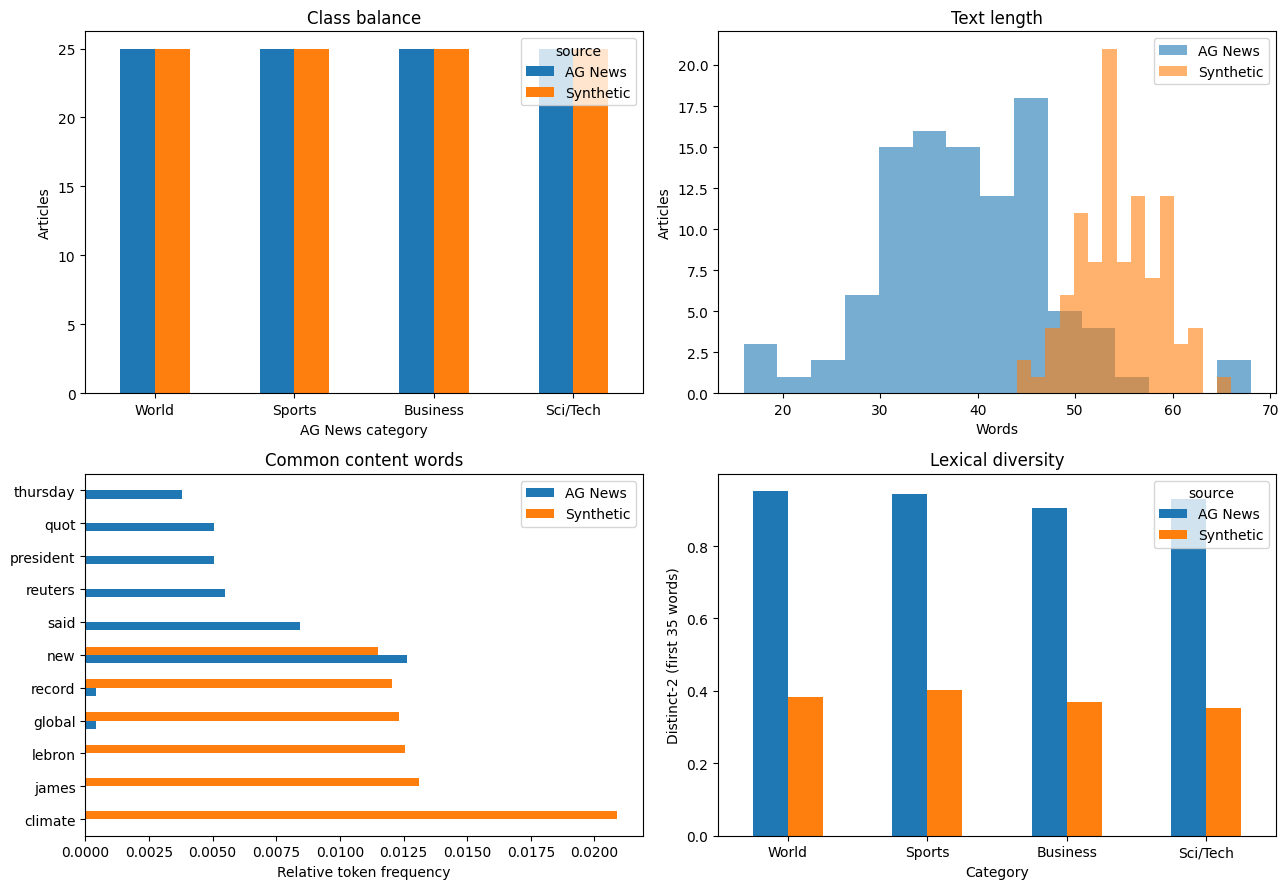

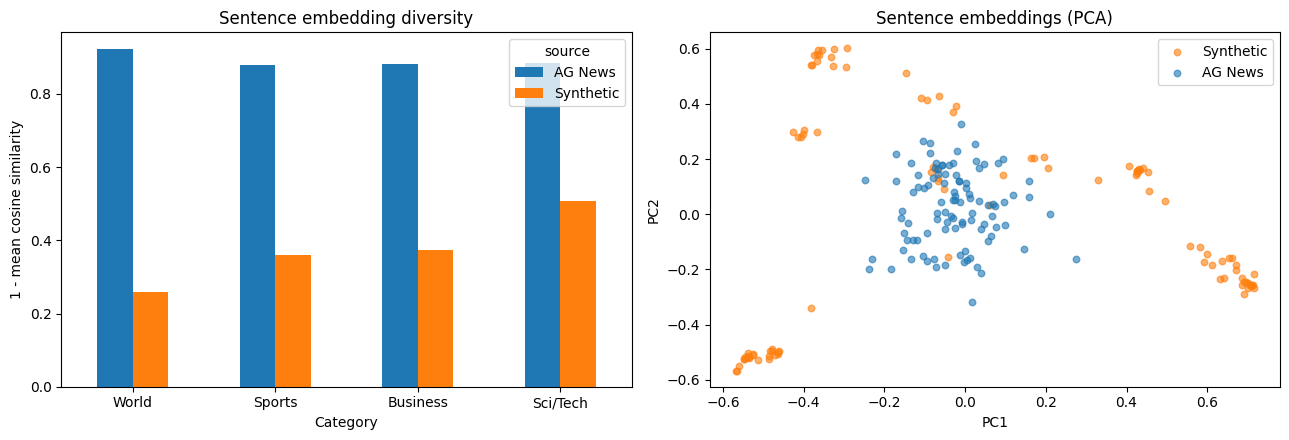

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
class_counts.T.reindex(CATEGORIES.values()).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(title="Class balance", xlabel="AG News category", ylabel="Articles")
for source, frame in data.groupby("source"):
    axes[0, 1].hist(frame.word_count, bins=15, alpha=0.6, label=source)
axes[0, 1].set(title="Text length", xlabel="Words", ylabel="Articles")
axes[0, 1].legend()
word_distribution.plot.barh(ax=axes[1, 0])
axes[1, 0].set(title="Common content words", xlabel="Relative token frequency", ylabel="")
lexical.pivot(index="category", columns="source", values="distinct_2_first35").reindex(CATEGORIES.values()).plot.bar(
    ax=axes[1, 1], rot=0)
axes[1, 1].set(title="Lexical diversity", xlabel="Category", ylabel="Distinct-2 (first 35 words)")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
semantic.pivot(index="category", columns="source", values="semantic_diversity").reindex(CATEGORIES.values()).plot.bar(
    ax=axes[0], rot=0)
axes[0].set(title="Sentence embedding diversity", xlabel="Category", ylabel="1 - mean cosine similarity")
comparison_vectors = np.vstack([syn_vectors, real_vectors[real.index.to_numpy()]])
projected = PCA(n_components=2, random_state=42).fit_transform(comparison_vectors)
for source, start, stop in (("Synthetic", 0, 100), ("AG News", 100, 200)):
    axes[1].scatter(projected[start:stop, 0], projected[start:stop, 1],
                    s=22, alpha=0.6, label=source,
                    color={"AG News": "tab:blue", "Synthetic": "tab:orange"}[source])
axes[1].set(title="Sentence embeddings (PCA)", xlabel="PC1", ylabel="PC2")
axes[1].legend()
fig.tight_layout()
plt.show()

The pilot is balanced with no missing or exact-duplicate texts, but 206 of 1,200 within-class synthetic pairs have embedding cosine at least 0.90. The real articles are older and contain byline artifacts, so comparisons are descriptive.